In [11]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "t2m":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "strd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "ssrd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc",
    "rf":   r"C:\greenland\sf_tp_rf.nc",
    "tcc":  r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取夏季 (JJA) 年度均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return summer_mean

def mk_trend_per_decade(y):
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    # ✅ 检查CSV是否已存在（只检查一个，因为两个总是同时生成）
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue
    
    # 打开数据集
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue
    
    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")
    
    # ---- 均值 + MK 趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")
    
    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values
    
    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\\greenland\\1995bu\\fig4")


===== Processing t2m =====
⏭️  t2m 的CSV已存在，跳过

===== Processing strd =====
⏭️  strd 的CSV已存在，跳过

===== Processing ssrd =====
✅ Summer mean shape: (75, 239, 612)
⏳ Calculating MK trend per grid...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_ssrd_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_ssrd_SlidingTrend.csv

===== Processing rf =====
⏭️  rf 的CSV已存在，跳过

===== Processing tcc =====
⏭️  tcc 的CSV已存在，跳过

✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\greenland\1995bu\fig4


In [2]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "sf":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "tp":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "hcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "lcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "vimdf": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取每年夏季(JJA)均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    da_summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return da_summer_mean

def mk_trend_per_decade(y):
    """对单点时间序列做MK趋势检验"""
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点多年均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    """计算滑动趋势矩阵"""
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue

    # 打开文件
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue

    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")

    # ---- 均值 + MK趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")

    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values

    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\\Users\\greenlandProject\\ERA5LAND\\ProcessFile")



===== Processing sf =====
⏭️  sf 的CSV已存在，跳过

===== Processing tp =====
⏭️  tp 的CSV已存在，跳过

===== Processing hcc =====
⏭️  hcc 的CSV已存在，跳过

===== Processing lcc =====
⏭️  lcc 的CSV已存在，跳过

===== Processing vimdf =====
✅ Summer mean shape: (76, 95, 244)
⏳ Calculating MK trend per grid...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_SlidingTrend.csv

✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\Users\greenlandProject\ERA5LAND\ProcessFile


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression

# ===== 路径 (Path - 请根据你的实际路径修改) =====
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含"albedo"的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 创建 DataFrame 并保存为 CSV =====
# 创建 DataFrame，行索引和列索引都是年份
df = pd.DataFrame(trend_matrix, index=years, columns=years)

# 保存为 CSV 文件
df.to_csv(output_path, index=True, na_rep='')
print(f"✅ CSV file saved to: {output_path}")

# 显示前几行预览
print("\n前5行5列预览:")
print(df.iloc[:5, :5])

ds.close() # 关闭 xarray 数据集


✅ Data range: 1950–2024 (75 years)
✅ CSV file saved to: C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv

前5行5列预览:
      1950  1951      1952      1953      1954
1950   NaN   NaN  0.004835  0.002649  0.002529
1951   NaN   NaN       NaN -0.001646  0.000322
1952   NaN   NaN       NaN       NaN  0.002311
1953   NaN   NaN       NaN       NaN       NaN
1954   NaN   NaN       NaN       NaN       NaN


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")



────────────────────────────────────────────────────────────────────────────────
【文件路径】
────────────────────────────────────────────────────────────────────────────────
C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc

────────────────────────────────────────────────────────────────────────────────
【基本打开（decode_cf=False / True）】
────────────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=False）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'time']
  dims:      {'lat': 237, 'lon': 612, 'time': 75}
  dataset attrs (0):
    (no attrs)

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=True）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'tim

C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:148: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_raw.dims)}")
C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:155: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_cf.dims)}")


C:\Users\11823\AppData\Local\Temp\ipykernel_35412\2541842929.py:269: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


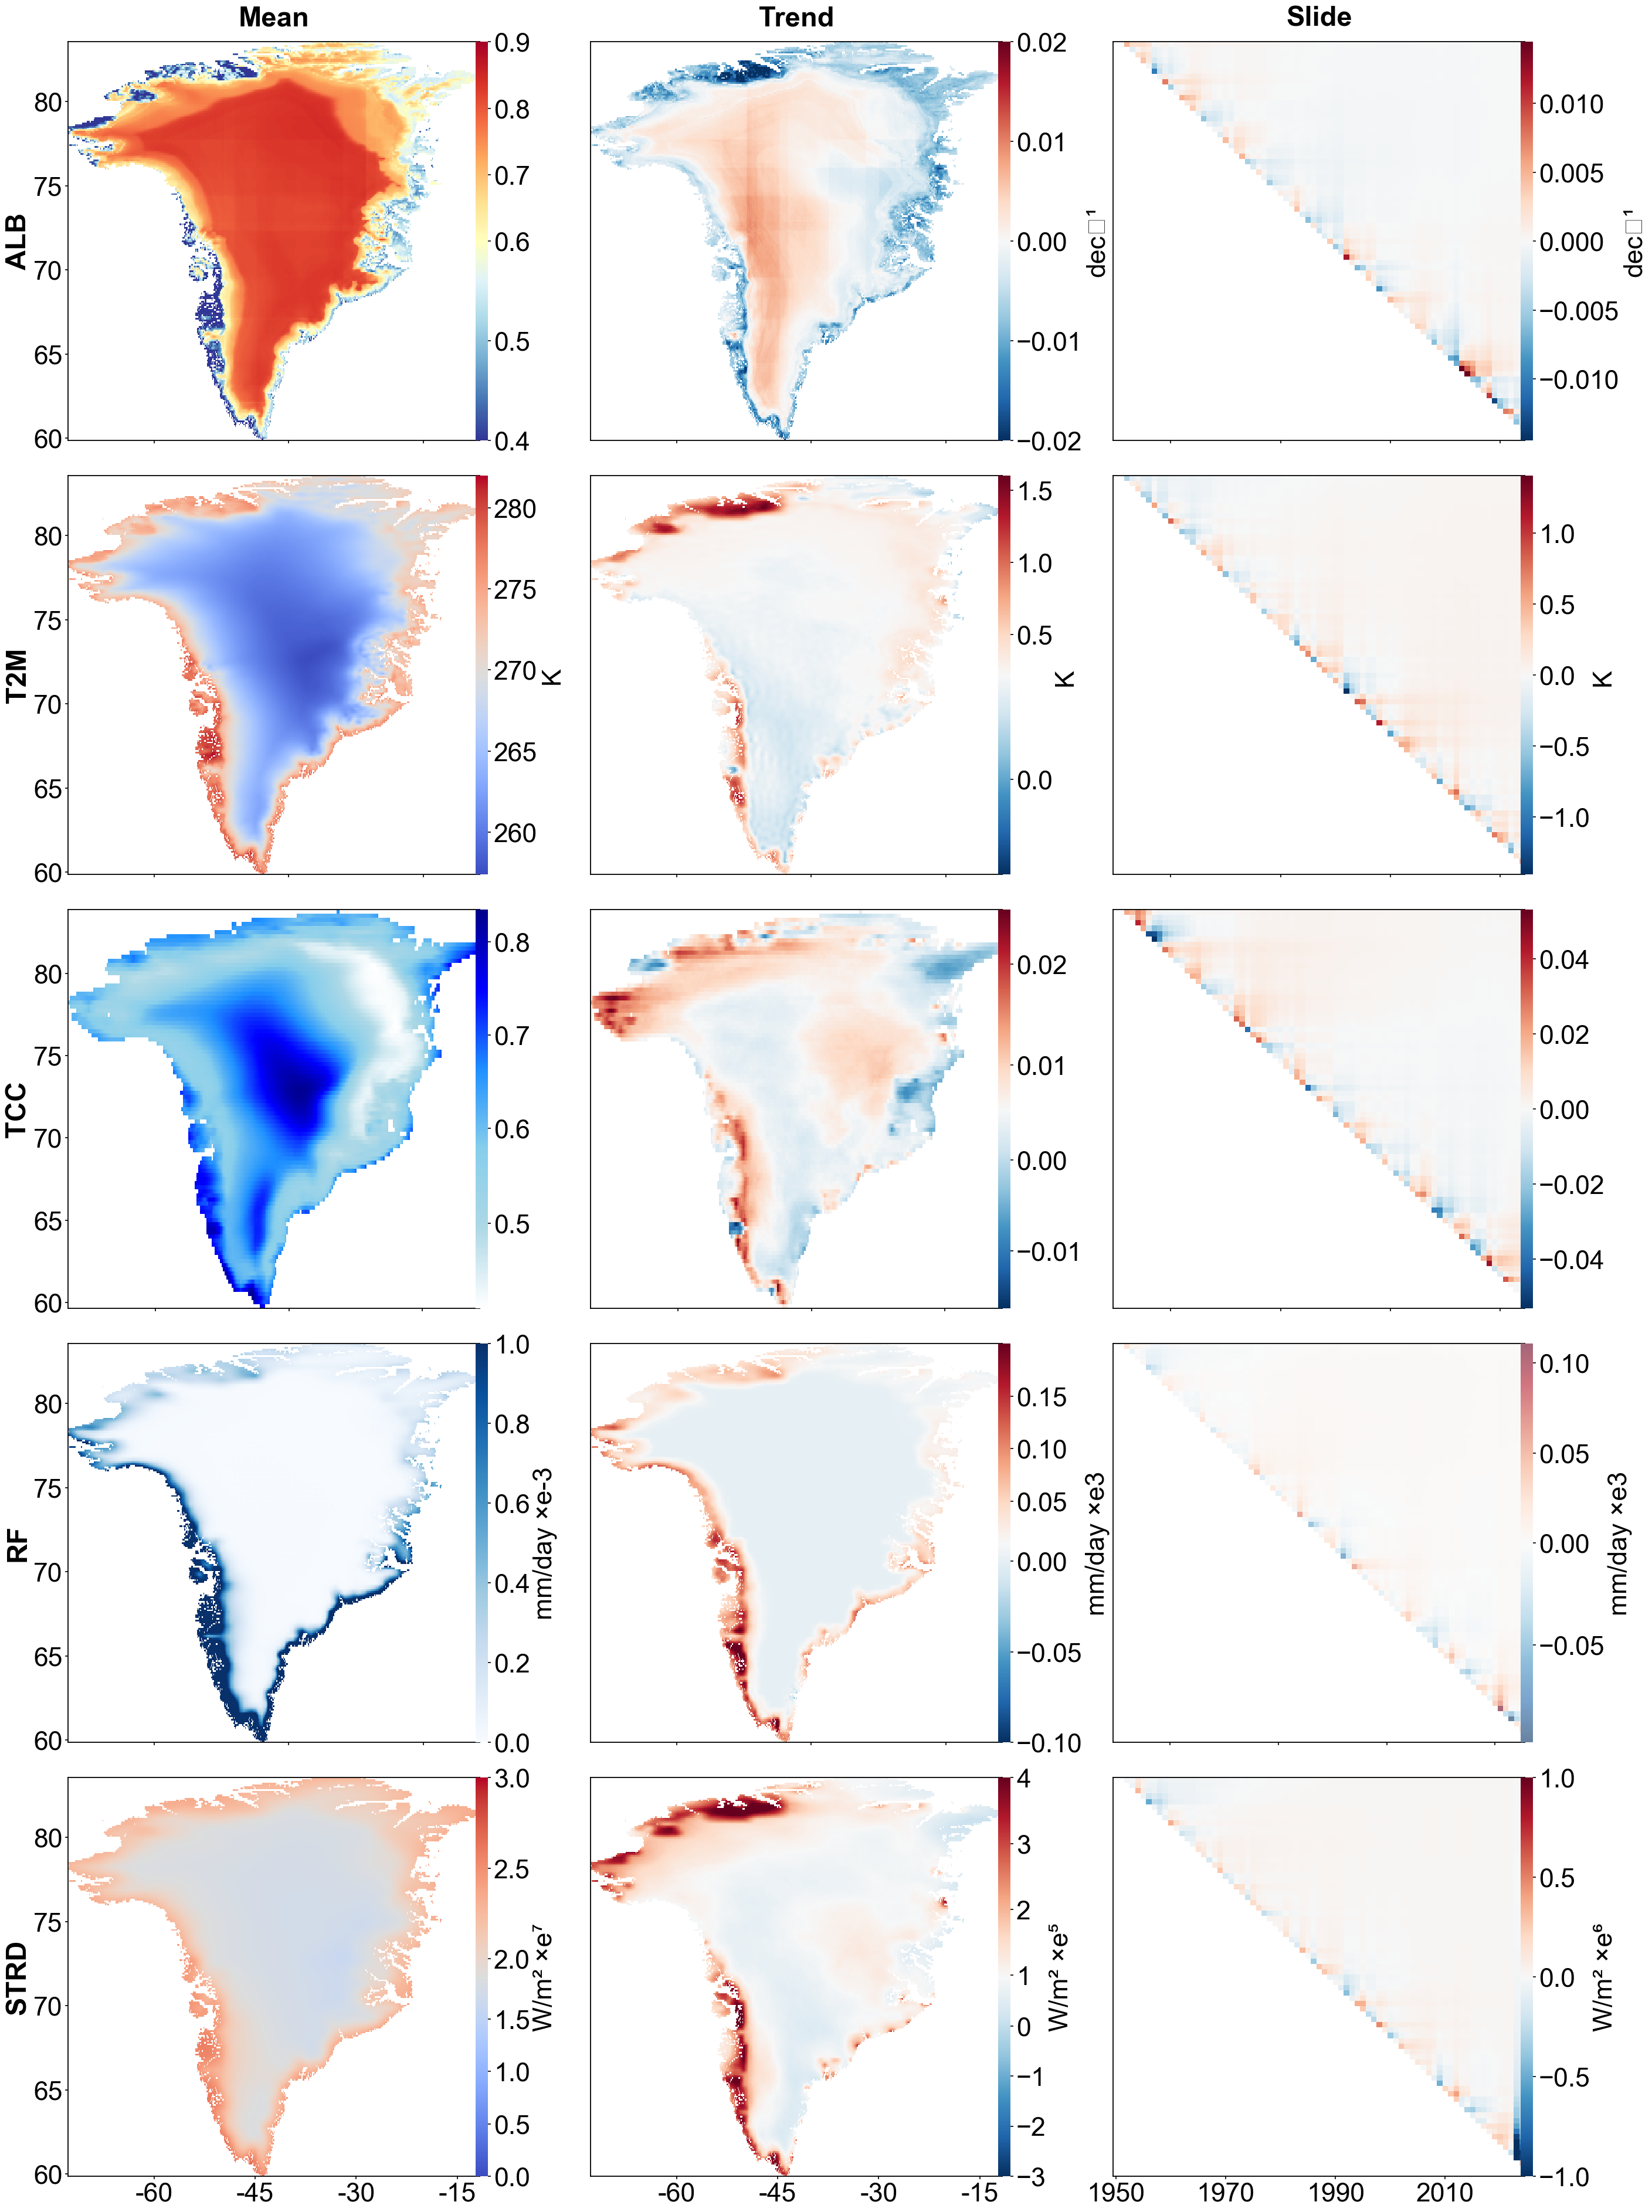

In [1]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel (alb / t2m / tcc / rf / strd)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ===== 参数区 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.07
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig4_5x3panel.png"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

fig = plt.figure(figsize=(27, 40))  # 增高画布
VARS = ["alb", "t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows

axes = []

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        CBAR_WIDTH, CBAR_PAD = "3%", 0.02

        # ================= ALBEDO =================
        if var == "alb":
            meantrend_csv = f"{DATA_DIR}\\Greenland_alb_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_alb_SlidingTrend.csv"

            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            mean_cmap = plt.cm.RdYlBu_r
            trend_cmap = plt.cm.RdBu_r

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values,
                                   cmap=mean_cmap,
                                   norm=TwoSlopeNorm(vmin=0.4, vcenter=0.6, vmax=0.9),
                                   shading="auto")
                label = " "
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values,
                                   cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02),
                                   shading="auto")
                label = "dec⁻¹"
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "dec⁻¹"

        # ================= 其他变量直接复用原逻辑 =================
        elif var == "t2m":
            meantrend_csv = f"{DATA_DIR}\\Greenland_t2m_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_t2m_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
                label = "K"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX),
                                   shading="auto")
                label = "K "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "K "

        elif var == "tcc":
            meantrend_csv = f"{DATA_DIR}\\Greenland_tcc_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_tcc_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            colors_cloud = ['white','lightblue','skyblue','dodgerblue','blue','darkblue']
            cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)
            vcenter_mean = 0.62
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=cmap_cloud,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(mean_grid), vcenter=vcenter_mean, vmax=np.nanmax(mean_grid)),
                                   shading="auto")
                label = ""
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=np.nanmedian(trend_grid), vmax=np.nanmax(trend_grid)),
                                   shading="auto")
                label = " "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = " "

        elif var == "rf":
            meantrend_csv = f"{DATA_DIR}\\Greenland_rf_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_rf_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals = slide.to_numpy(dtype=float) * 1e3
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="Blues",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                label = r"mm/day ×e-3"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.01, vmax=0.2),
                                   shading="auto")
                label = r"mm/day ×e3"
            else:
                cmap_slide = plt.cm.RdBu_r
                colors_slide = cmap_slide(np.linspace(0,1,256)); colors_slide[:,-1]=0.6
                cmap_slide_light = mcolors.ListedColormap(colors_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)),
                                   shading="auto")
                ax.invert_yaxis()
                label = r"mm/day ×e3"

        elif var == "strd":
            meantrend_csv = f"{DATA_DIR}\\Greenland_strd_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_strd_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
            df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
            df = df.dropna(subset=["lat","lon"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid  = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            trend_grid = trend_grid / 1e5
            lats = mean_grid.index.values.astype(float)
            lons = mean_grid.columns.values.astype(float)
            MEAN_VMIN, MEAN_VMAX = 0, 3
            TREND_VMIN, TREND_VMAX = -3, 4
            MEAN_VCENTER  = float(np.nanmedian(mean_grid.values / 1e7))
            TREND_VCENTER = float(np.nanmedian(trend_grid.values))
            eps = 1e-9
            MEAN_VCENTER = np.clip(MEAN_VCENTER, MEAN_VMIN+eps, MEAN_VMAX-eps)
            TREND_VCENTER = np.clip(TREND_VCENTER, TREND_VMIN+eps, TREND_VMAX-eps)
            slide = pd.read_csv(sliding_csv, index_col=0)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float) / 1e6
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm",
                                   norm=norm_mean, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁷"
            elif col == "Trend":
                norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=norm_trend, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁵"
            else:
                vmax_slide = 1.0
                norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=norm_slide, shading="auto")
                ax.invert_yaxis()
                label = "W/m² ×e⁶"

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax)
        cb.set_label(label, fontsize=FONT_SIZE)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=FONT_SIZE)

        # ===== 样式统一 =====
        ax.tick_params(labelsize=FONT_SIZE)
        if i < n_rows - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=20)
        if j == 0:
            ax.text(-0.09, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=FONT_SIZE)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()


✅ Shapefiles loaded: 9 basins | 4 contours


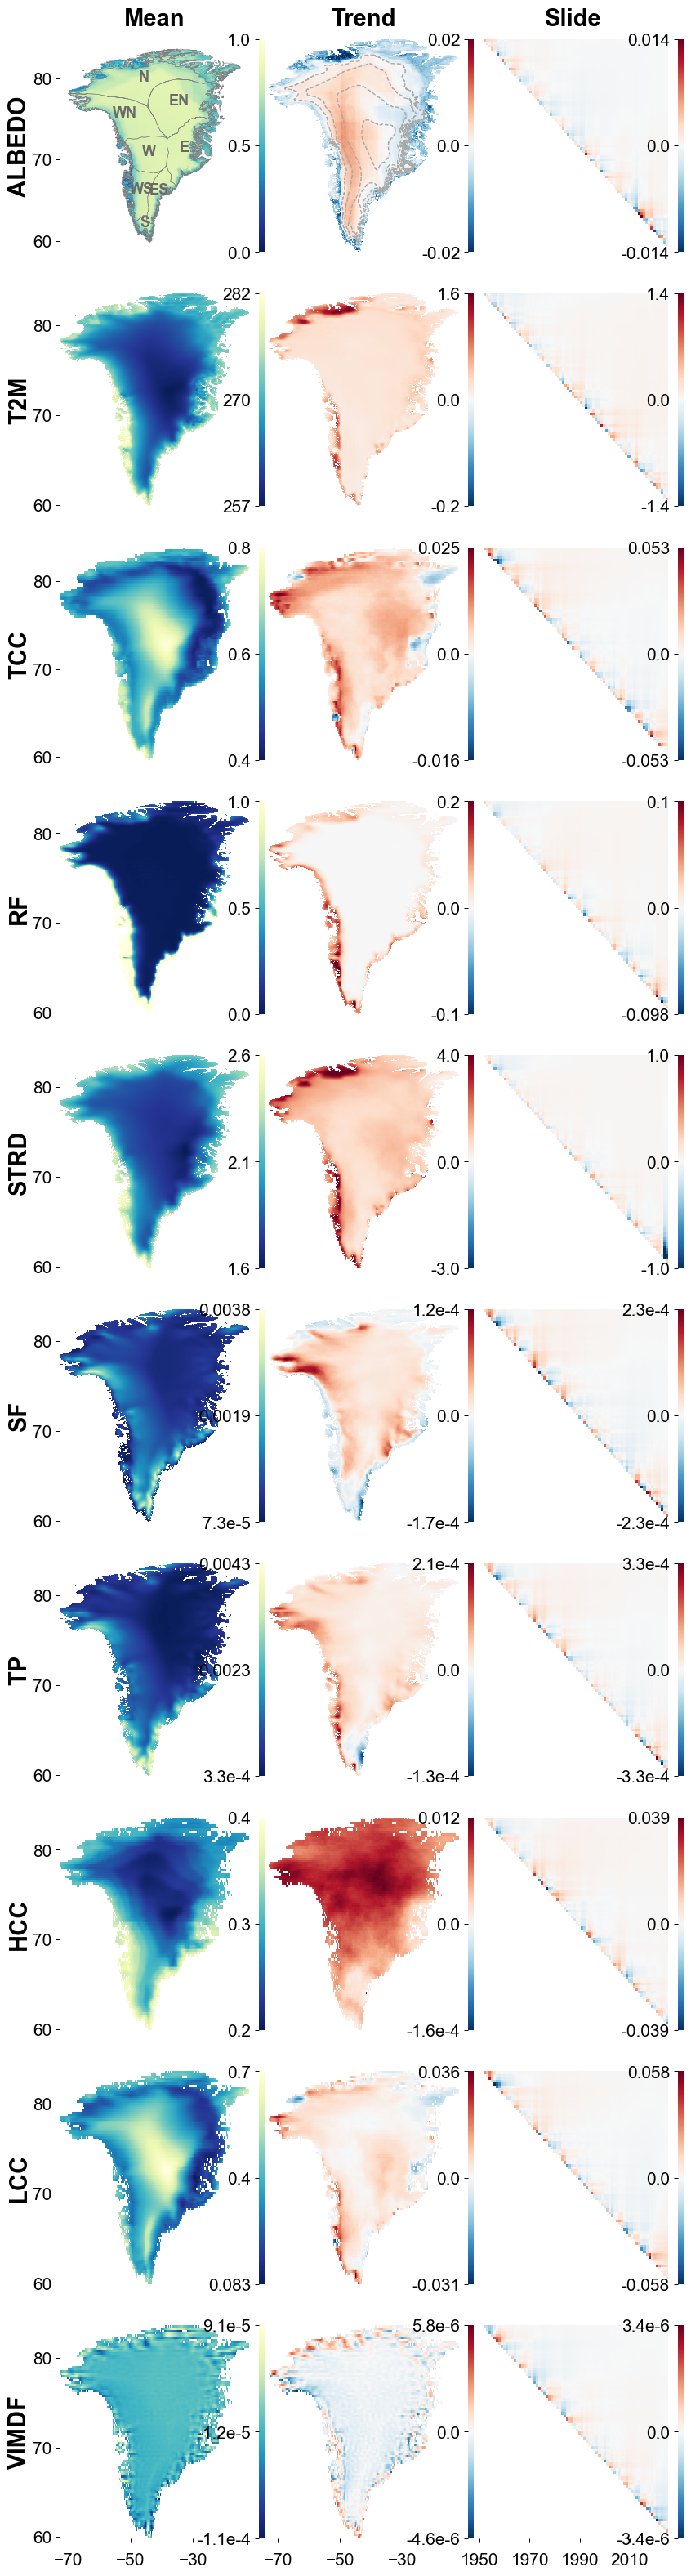

In [8]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel
(ALB fixed aspect ratio, no deformation, thicker contours)

【修改版 v7.3：统一 "Mean" 列配色为 'YlGnBu_r' (亮色代表高值)】
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 19
TICK_FONT_SIZE = FONT_SIZE - 4 # 15
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_10x3panel_final_v7_ticks_refined.png") # (路径保持v7)

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M", "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        gdf["abbr"] = abbr_map.get(os.path.splitext(fname)[0], fname)
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

print(f"✅ Shapefiles loaded: {len(basins_all)} basins | {len(contour_gdf)} contours")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(8.1, 33.6))

VARS = ["albedo", "t2m", "tcc", "rf", "strd",
        "sf", "tp", "hcc", "lcc", "vimdf"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

PAD_TITLE = 12
PAD_XAXIS = 9

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        CBAR_WIDTH, CBAR_PAD = "3%", 0.08 

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)
        
        label = ""

        # ================= ALBEDO =================
        if var == "albedo":
            # [!! 修正 !!] Mean 列统一使用 YlGnBu_r (反向)
            mean_cmap = plt.cm.YlGnBu_r 
            trend_cmap = plt.cm.RdBu_r
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=mean_cmap,
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
                for _, row in basins_all.iterrows():
                    abbr = row["abbr"]
                    if abbr == "M": continue
                    x, y = row.geometry.centroid.x, row.geometry.centroid.y + 0.3
                    ax.text(x, y, abbr, fontsize=FONT_SIZE-6, color="dimgray",
                            ha="center", va="center", fontweight="bold", zorder=6)
                ax.set_aspect('auto', adjustable='box')
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    if isinstance(geom, (LineString, MultiLineString)): 
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for part in parts:
                            xs, ys = part.xy
                            ax.plot(xs, ys, color="darkgrey", linestyle="--",
                                    linewidth=1.0, zorder=5)
                ax.set_aspect('auto', adjustable='box')
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= t2m =================
        elif var == "t2m":
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= tcc =================
        elif var == "tcc":
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= rf =================
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)), shading="auto")
                ax.invert_yaxis()
        
        # ================= strd =================
        elif var == "strd":
            trend_grid_scaled = trend_grid / 1e5
            vals_masked_scaled = vals_masked / 1e6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=4), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), shading="auto")
                ax.invert_yaxis()

        # ================= (sf, tp, hcc, lcc, vimdf) =================
        else: 
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", 
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # (三点刻度逻辑 保持 v2 修改)
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, 'vcenter'):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.set_label("", fontsize=FONT_SIZE) 
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE) 
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        
        # (刻度格式化 保持 v7 修改)
        formatted_ticks = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 100:
                s = "{:.0f}".format(t)
            elif abs(t) >= 1:
                s = "{:.1f}".format(t)
            elif abs(t) < 0.001: 
                s = "{:.1e}".format(t)
            elif abs(t) < 0.1: 
                s = "{:.2g}".format(t)
            else:
                s = "{:.1f}".format(t)
            
            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted_ticks.append(s)
        cb.set_ticklabels(formatted_ticks)
        
        # ===== 样式 =====
        ax.tick_params(labelsize=TICK_FONT_SIZE) 
        
        if i < n_rows - 1:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)
        else:
            if j < n_cols - 1: 
                ax.set_xticks([-70, -50, -30])
                ax.tick_params(axis='x', pad=PAD_XAXIS)
        
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)
        if j == 0:
            ax.text(-0.15, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=TICK_FONT_SIZE, axis='x', pad=PAD_XAXIS)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

⚠️ 未找到 z500，跳过
⚠️ 未找到 z200，跳过


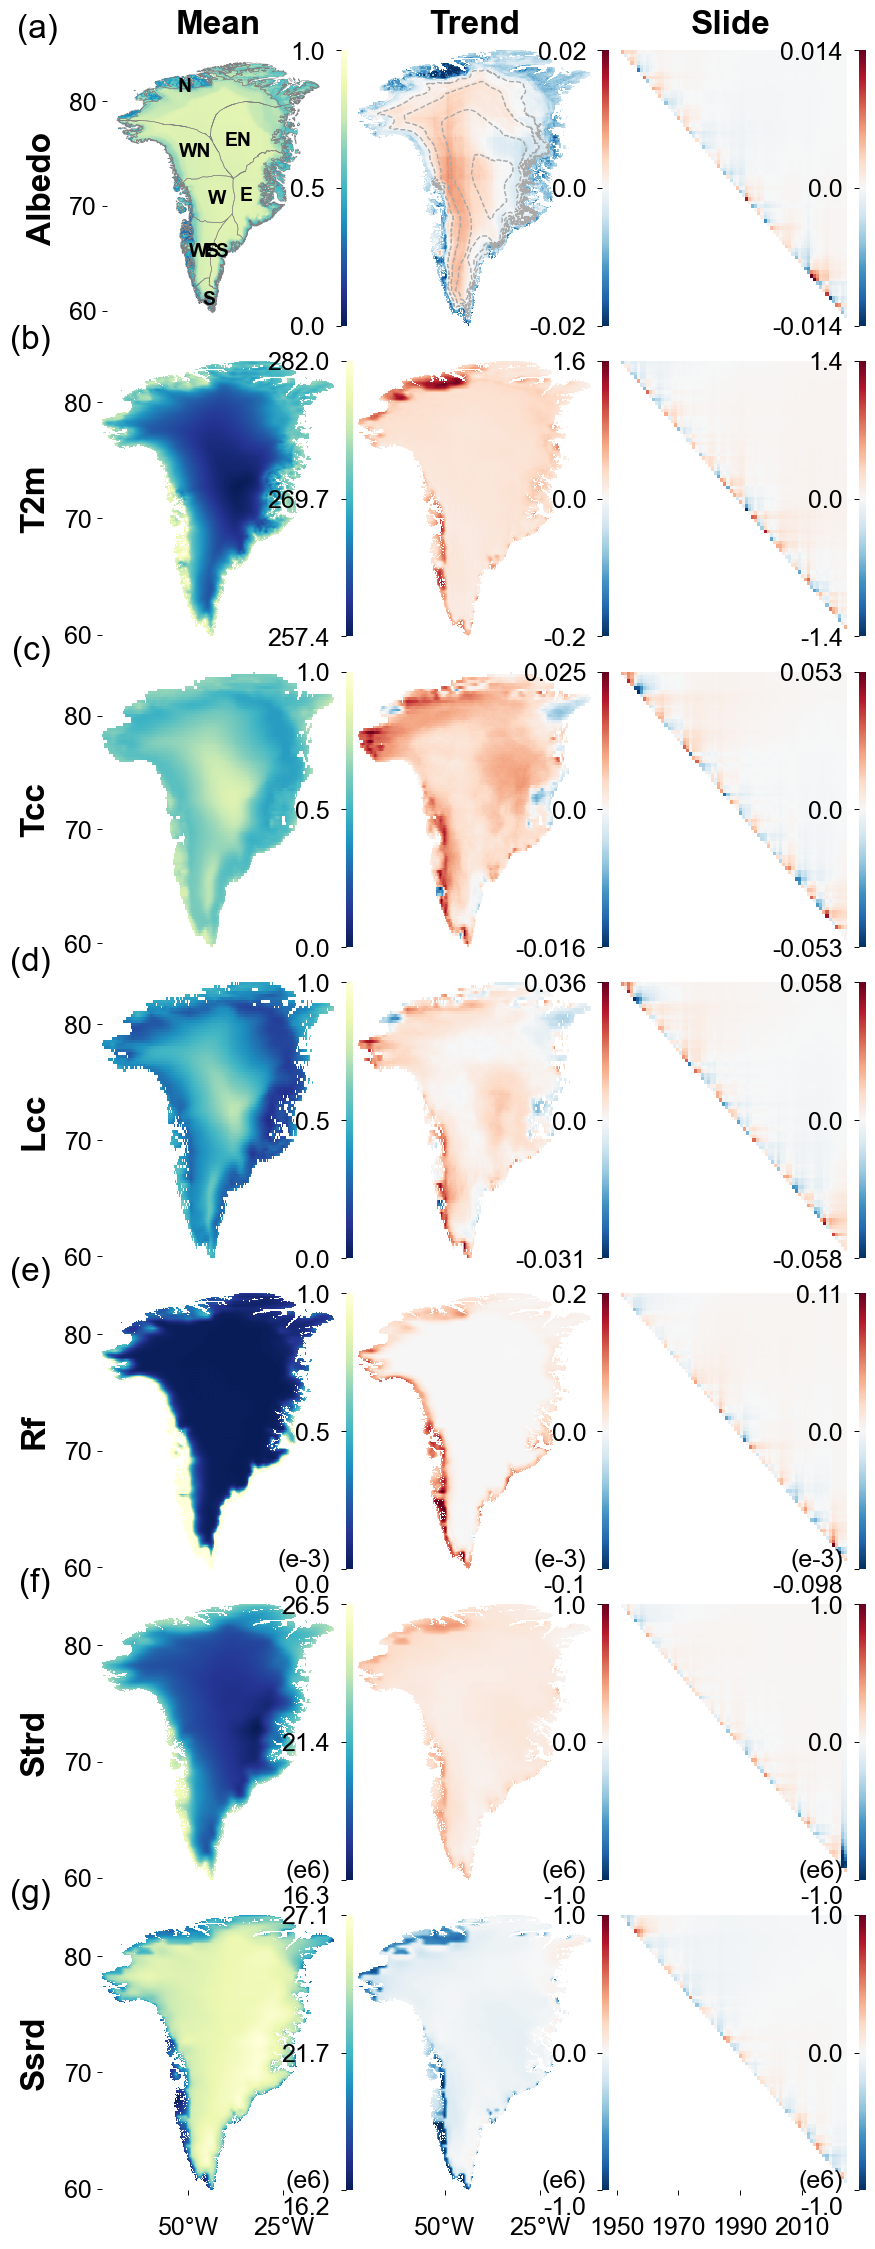

图像已保存至: C:\greenland\1995bu\fig4\Fig4_7x3panel_v8_7_labels_corrected_v3.png


In [3]:
# -*- coding: utf-8 -*-
"""
Final N×3 Greenland Climate Panel (v8.7)
- 每行只显示一个小标题(a)(b)(c)在第一列
- X轴经度改为50°W格式
- STRD和SSRD的Trend色标改为-1到1
- [修改] 在第一幅图(a, Mean)上添加流域标签
- [修正 v3] 移除 M 标签, 放大所有标签, 上移 N 标签
"""

import os
import sys
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.ticker import FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 22
TICK_FONT_SIZE = FONT_SIZE - 4
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ===== 经度格式化函数 =====
def format_longitude(x, pos):
    """将经度转换为 50°W 格式"""
    if x == 0:
        return "0°"
    elif x < 0:
        return f"{int(abs(x))}°W"
    else:
        return f"{int(x)}°E"

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M",  
    "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        
        basin_name = os.path.splitext(fname)[0]
        gdf["abbr"] = abbr_map.get(basin_name, basin_name) 
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

# ========== 预检查数据文件 ==========
VARS_DESIRED = [
    "albedo", "t2m", "z500", "z200", "tcc",
    "lcc", "rf", "strd", "ssrd"
]

VAR_DISPLAY_NAMES_ALL = {
    "albedo": "Albedo", "t2m": "T2m", "z500": "500 hPa Z",
    "z200": "200 hPa Z", "tcc": "Tcc", "lcc": "Lcc",
    "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd"
}

VARS_PRESENT = []
VAR_DISPLAY_NAMES_PRESENT = {}

for var in VARS_DESIRED:
    meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
    sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

    if os.path.exists(meantrend_csv) and os.path.exists(sliding_csv):
        VARS_PRESENT.append(var)
        VAR_DISPLAY_NAMES_PRESENT[var] = VAR_DISPLAY_NAMES_ALL.get(var)
    else:
        print(f"⚠️ 未找到 {var}，跳过")

if not VARS_PRESENT:
    print("错误：没有任何变量数据")
    sys.exit()

COL_NAMES = ["Mean", "Trend", "Slide"]
n_rows = len(VARS_PRESENT)
n_cols = 3

FIG_HEIGHT_PER_ROW = 3.36
FIG_HEIGHT_NEW = FIG_HEIGHT_PER_ROW * n_rows

SAVE_PATH = os.path.join(DATA_DIR, f"Fig4_{n_rows}x3panel_v8_7_labels_corrected_v3.png") # 更改了保存名称
fig = plt.figure(figsize=(8.1, FIG_HEIGHT_NEW))

left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows

axes = []
PAD_TITLE = 12
PAD_X_AXIS = 9

# ========== 小标题 (a)... ==========
ROW_LABELS = [f"({chr(97+i)})" for i in range(n_rows)]

# ========== 绘图 ==========
for i, var in enumerate(VARS_PRESENT):

    unit_label = ""
    if var == "rf":
        unit_label = "(e-3)"
    elif var in ["strd", "ssrd"]:
        unit_label = "(e6)"

    for j, col in enumerate(COL_NAMES):

        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)

        # 关闭框线
        for s in ax.spines.values():
            s.set_visible(False)

        mean_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        slide_csv = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(mean_csv).dropna(subset=["mean", "trend_per_decade"])
        slide = pd.read_csv(slide_csv, index_col=0)

        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

        lats = mean_grid.index.values.astype(float)
        lons = mean_grid.columns.values.astype(float)

        years = slide.columns.astype(int).values
        slide_years = slide.index.astype(int).values
        vals = slide.to_numpy(float)

        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)

        # ---------------- ALBEDO ----------------
        if var == "albedo":
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                # 此处的 basins_all.boundary.plot(...) 已被删除
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    if isinstance(geom, (LineString, MultiLineString)):
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for p in parts:
                            xs, ys = p.xy
                            ax.plot(xs, ys, "darkgrey", linestyle="--", linewidth=1.0)
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ---------------- T2M ----------------
        elif var == "t2m":
            TREND_VMIN, TREND_VMAX = -0.2, 1.6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ---------------- TCC ----------------
        elif var == "tcc":
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # ---------------- LCC ----------------
        elif var == "lcc":
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # ---------------- RF ----------------
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2),
                                   shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)),
                                   shading="auto")
                ax.invert_yaxis()

        # ---------------- STRD ----------------
        elif var == "strd":
            mean_scaled = mean_grid.values / 1e6
            trend_scaled = trend_grid.values / 1e6
            vals_scaled = vals_masked / 1e6

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
                                   shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
                                   shading="auto")
                ax.invert_yaxis()

        # ---------------- SSRD ----------------
        elif var == "ssrd":
            mean_scaled = mean_grid.values / 1e6
            trend_scaled = trend_grid.values / 1e6
            vals_scaled = vals_masked / 1e6

            if col == "Mean":
                im = ax.pcolormesh(
                    lons, lats, mean_scaled, cmap="YlGnBu_r",
                    norm=Normalize(vmin=np.nanmin(mean_scaled),
                                   vmax=np.nanmax(mean_scaled)),
                    shading="auto"
                )
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
                                   shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
                                   shading="auto")
                ax.invert_yaxis()

        # ---------------- 其他变量 ----------------
        else:
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=np.nanmin(mean_grid),
                                                  vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid),
                                                     vcenter=0,
                                                     vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # ==========================================================
        # --- [新代码开始] ---
        # 仅在第一行 (i==0) 的第一列 (col=="Mean") 绘制流域边界和标签
        # ==========================================================
        if i == 0 and col == "Mean":
            # 1. 绘制流域边界
            basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)

            # 2. 设置文字标签样式
            text_props = {
                'fontsize': FONT_SIZE - 8, # [修正] 放大字体 (14pt)
                'fontweight': 'bold',
                'color': 'black',
                'ha': 'center',
                'va': 'center',
                'zorder': 10  # 确保在顶层
            }

            # 3. 遍历所有流域并添加标签
            for idx, row in basins_all.iterrows():
                center = row.geometry.representative_point()
                label = row["abbr"]

                # [修正] 移除 'M' (Melt) 标签
                if label == "M":
                    continue 

                # [修正] 对特定标签位置进行微调
                x_offset, y_offset = 0, 0
                if label == "N":
                    y_offset = 2.0  # [修正] 向上移动 (之前是 -2.0)
                elif label == "WN":
                    x_offset = 1.0  # 向右移动
                elif label == "W":
                    x_offset = 1.5
                elif label == "WS":
                    x_offset = 1.0
                elif label == "S":
                    y_offset = -0.5 # 稍微向下移动
                elif label == "E":
                    x_offset = -0.8 # 向左移动
                elif label == "EN":
                    x_offset = -1.0
                elif label == "ES":
                    x_offset = -0.8

                ax.text(center.x + x_offset, center.y + y_offset, label, **text_props)
        # --- [新代码结束] ---
        # ==========================================================

        # ================= colorbar =================
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, "vcenter"):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        cb_ax = inset_axes(ax, width="3%", height="100%", loc='right',
                           bbox_to_anchor=(0.08, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0)

        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE, pad=8)
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')

        formatted = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 1:
                s = f"{t:.1f}"
            elif abs(t) < 0.001:
                s = f"{t:.1e}"
            else:
                s = f"{t:.2g}"

            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted.append(s)

        if unit_label:
            formatted[0] = f"{unit_label}\n{formatted[0]}"
        cb.set_ticklabels(formatted)

        # ========== 样式 ==========
        ax.tick_params(labelsize=TICK_FONT_SIZE)

        # -------- X 轴刻度 --------
        if i == n_rows - 1:
            ax.tick_params(axis='x', pad=PAD_X_AXIS + 6)
            # *** 添加经度格式化 ***
            if col in ["Mean", "Trend"]:
                ax.xaxis.set_major_formatter(FuncFormatter(format_longitude))
        else:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)

        # -------- 去掉多余 Y 轴 --------
        if j > 0:
            ax.tick_params(left=False, labelleft=False)

        # -------- 顶部列标题 --------
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)

        # -------- 每行左侧变量名 --------
        if j == 0:
            name = VAR_DISPLAY_NAMES_PRESENT[var]
            ax.text(-0.22, 0.5, name, transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

        # -------- 每行左上角 (a)(b)... 只在第一列显示 --------
        if j == 0:  # *** 修改：只在第一列显示小标题 ***
            ax.text(-0.22, 1.02, ROW_LABELS[i], transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="normal",
                    va='bottom', ha='right')


# ===== 底部年份刻度统一 =====
if axes:
    axes[-1].set_xticks(np.arange(1950, 2030, 20))
    axes[-1].tick_params(axis='x', pad=PAD_X_AXIS + 6)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"图像已保存至: {SAVE_PATH}")